# 02f - Backtest sem vazamento com os decks do NEWAVE (fev/2025 a set/2026)

Simula alguém **sentado na data de cada deck** prevendo a bandeira de M+1 a M+7 (regra do backtest no `CLAUDE.md`).

| Insumo | Fonte (disponível na data do deck) |
|---|---|
| Geração, ENA e custo marginal das 2.000 séries | saídas do deck (`ghtotsin`, `eafbm001–004`, `cmarg001–004`) |
| ANDE (+ consumo interno de Itaipu), PCH e carga dos submercados do mês-alvo | entradas do deck (`c_adic.dat`, `sistema.dat`) |
| GF_band, fatores de perda da CCEE, PLD mín/máx | boletim do mês do deck (publicado junto com o deck) |
| σ da probabilidade | só erros de previsões cujo mês-alvo terminou **antes** do mês do deck (mínimo de 8) |
| **ENA de referência** | **ORÁCULO**: ENA real de cada mês (será trocada pela previsão do ECMWF) |

**Método (mesma série):** 25 séries pela trajetória de ENA do SIN do início do deck até o mês-alvo (mais peso nos meses
recentes); GSF e PLD gatilho médios dessas séries; **cor = cor da média**; probabilidade de cada cor = X real ~ Normal(X médio, σ).

**Horizonte:** h = 1 a 7 meses após o mês do deck (7 = alcance da previsão sazonal do ECMWF) (o mês do próprio deck, h = 0, é decidido junto com a publicação do deck).

**O que é fora da amostra aqui:** ANDE/PCH/carga, GF_band, σ. **Dentro da amostra:** k = 25 e a meia-vida de 2 meses
(escolhidos com 2026). **Oráculo:** a ENA de referência.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import backtest, graficos, load, newave

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.index = base.index.to_period("M")
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
base["x_real"] = base.pld_gatilho_boletim * (1 - base.gsf_band_boletim).clip(lower=0)
ORD = ["Verde", "Amarela", "Vermelha 1", "Vermelha 2"]
backtest.decks_disponiveis()

[(2025, 2),
 (2025, 3),
 (2025, 4),
 (2025, 5),
 (2025, 6),
 (2025, 8),
 (2025, 11),
 (2025, 12),
 (2026, 1),
 (2026, 2),
 (2026, 3),
 (2026, 4),
 (2026, 5),
 (2026, 9)]

## 1. Previsões de cada deck

In [2]:
prev = pd.concat([backtest.prever_deck(a, m, base) for a, m in backtest.decks_disponiveis()], ignore_index=True)
prev = prev.merge(base[["cor_oficial", "x_real", "gsf_band_boletim", "pld_gatilho_boletim"]],
                  left_on="alvo", right_index=True)
prev["erro_x"] = prev.x_real - prev.x_medio
prev.head()

,deck,alvo,h,gsf_medio,pld_medio,x_medio,cor_media,cor_oficial,x_real,gsf_band_boletim,pld_gatilho_boletim,erro_x
0,2025-02,2025-02,0,1.060,61.532,0.000,Verde,Verde,0.000,1.060,58.600,0.000
1,2025-02,2025-03,1,1.040,89.527,0.000,Verde,Verde,0.000,1.030,264.690,0.000
2,2025-02,2025-04,2,1.000,123.054,0.000,Verde,Verde,12.482,0.940,208.030,12.482
3,2025-02,2025-05,3,0.880,168.975,20.277,Verde,Amarela,41.121,0.830,241.890,20.844
4,2025-02,2025-06,4,0.770,240.907,55.409,Amarela,Vermelha 1,77.588,0.750,310.350,22.179


## 2. σ andando no tempo e probabilidade de cada cor

In [3]:
sigmas = {d: backtest.sigma_disponivel(prev, d) for d in prev.deck.unique()}
prev["sigma"] = prev.deck.map(lambda d: sigmas[d][0])
prev["n_erros_sigma"] = prev.deck.map(lambda d: sigmas[d][1])
probs = [newave.probabilidade_calibrada(x, s, g) if pd.notna(s) else pd.Series(np.nan, index=ORD)
         for x, s, g in zip(prev.x_medio, prev.sigma, prev.gsf_medio)]
for c in ORD:
    prev[f"p_{c}"] = [p[c] for p in probs]
prev["p_cor_real"] = [prev.loc[i, f"p_{c}"] for i, c in zip(prev.index, prev.cor_oficial)]
prev["p_cor_prevista"] = [prev.loc[i, f"p_{c}"] for i, c in zip(prev.index, prev.cor_media)]
obs = pd.DataFrame({c: (prev.cor_oficial == c).astype(float) for c in ORD})
prev["brier"] = ((prev[[f"p_{c}" for c in ORD]].to_numpy() - obs.to_numpy()) ** 2).sum(axis=1)
prev.loc[prev.sigma.isna(), "brier"] = np.nan
# referências ingênuas, conhecidas na data do deck
prev["cor_persistencia"] = prev.deck.map(base.cor_oficial)     # cor do mês do deck (já anunciada)
prev["cor_ano_anterior"] = (prev.alvo - 12).map(base.cor_oficial)
prev.to_parquet(load.DATA_PROCESSED / "backtest_newave.parquet")
pd.DataFrame({"σ": {str(d): s for d, (s, n) in sigmas.items()}, "n erros": {str(d): n for d, (s, n) in sigmas.items()}})

,σ,n erros
2025-02,NaN,0
2025-03,NaN,0
2025-04,NaN,0
2025-05,NaN,1
2025-06,NaN,5
2025-08,10.470,15
2025-11,10.845,32
2025-12,10.662,37
2026-01,11.899,42
2026-02,11.899,42


## 3. Resultado por horizonte (h = 1 a 7)

In [4]:
t = prev[prev.h >= 1]
acerto = lambda col: (lambda s: (s == t.loc[s.index, "cor_oficial"]).mean())
resumo = t.groupby("h").agg(
    previsoes=("alvo", "size"), acerto_cor_media=("cor_media", acerto("cor_media")),
    acerto_persistencia=("cor_persistencia", acerto("cor_persistencia")),
    acerto_ano_anterior=("cor_ano_anterior", acerto("cor_ano_anterior")),
    erro_medio_gsf=("gsf_medio", lambda s: (s - t.loc[s.index, "gsf_band_boletim"]).abs().mean()),
    erro_medio_pld=("pld_medio", lambda s: (s - t.loc[s.index, "pld_gatilho_boletim"]).abs().mean()),
    com_probabilidade=("p_cor_real", "count"), prob_media_cor_real=("p_cor_real", "mean"), brier=("brier", "mean"))
total = pd.DataFrame([{
    "previsoes": len(t), "acerto_cor_media": (t.cor_media == t.cor_oficial).mean(),
    "acerto_persistencia": (t.cor_persistencia == t.cor_oficial).mean(),
    "acerto_ano_anterior": (t.cor_ano_anterior == t.cor_oficial).mean(),
    "erro_medio_gsf": (t.gsf_medio - t.gsf_band_boletim).abs().mean(),
    "erro_medio_pld": (t.pld_medio - t.pld_gatilho_boletim).abs().mean(),
    "com_probabilidade": t.p_cor_real.count(), "prob_media_cor_real": t.p_cor_real.mean(), "brier": t.brier.mean()}], index=["total"])
pd.concat([resumo, total])

,previsoes,acerto_cor_media,acerto_persistencia,acerto_ano_anterior,erro_medio_gsf,erro_medio_pld,com_probabilidade,prob_media_cor_real,brier
1,14,0.714,0.571,0.500,0.033,92.432,9,0.731,0.315
2,13,0.692,0.308,0.462,0.050,86.783,8,0.761,0.300
3,13,0.615,0.154,0.308,0.040,65.429,8,0.719,0.312
4,13,0.769,0.154,0.231,0.035,55.971,8,0.790,0.225
5,13,0.615,0.154,0.231,0.046,43.397,8,0.728,0.311
6,12,0.667,0.167,0.167,0.039,47.847,7,0.722,0.340
7,11,0.909,0.273,0.182,0.037,63.744,6,0.817,0.110
total,89,0.708,0.258,0.303,0.040,65.617,54,0.750,0.279


## 4. Matriz das previsões (deck × mês-alvo)

Célula = cor da média; o número é a probabilidade dessa cor (quando já há histórico para o σ); ✗ = errou.

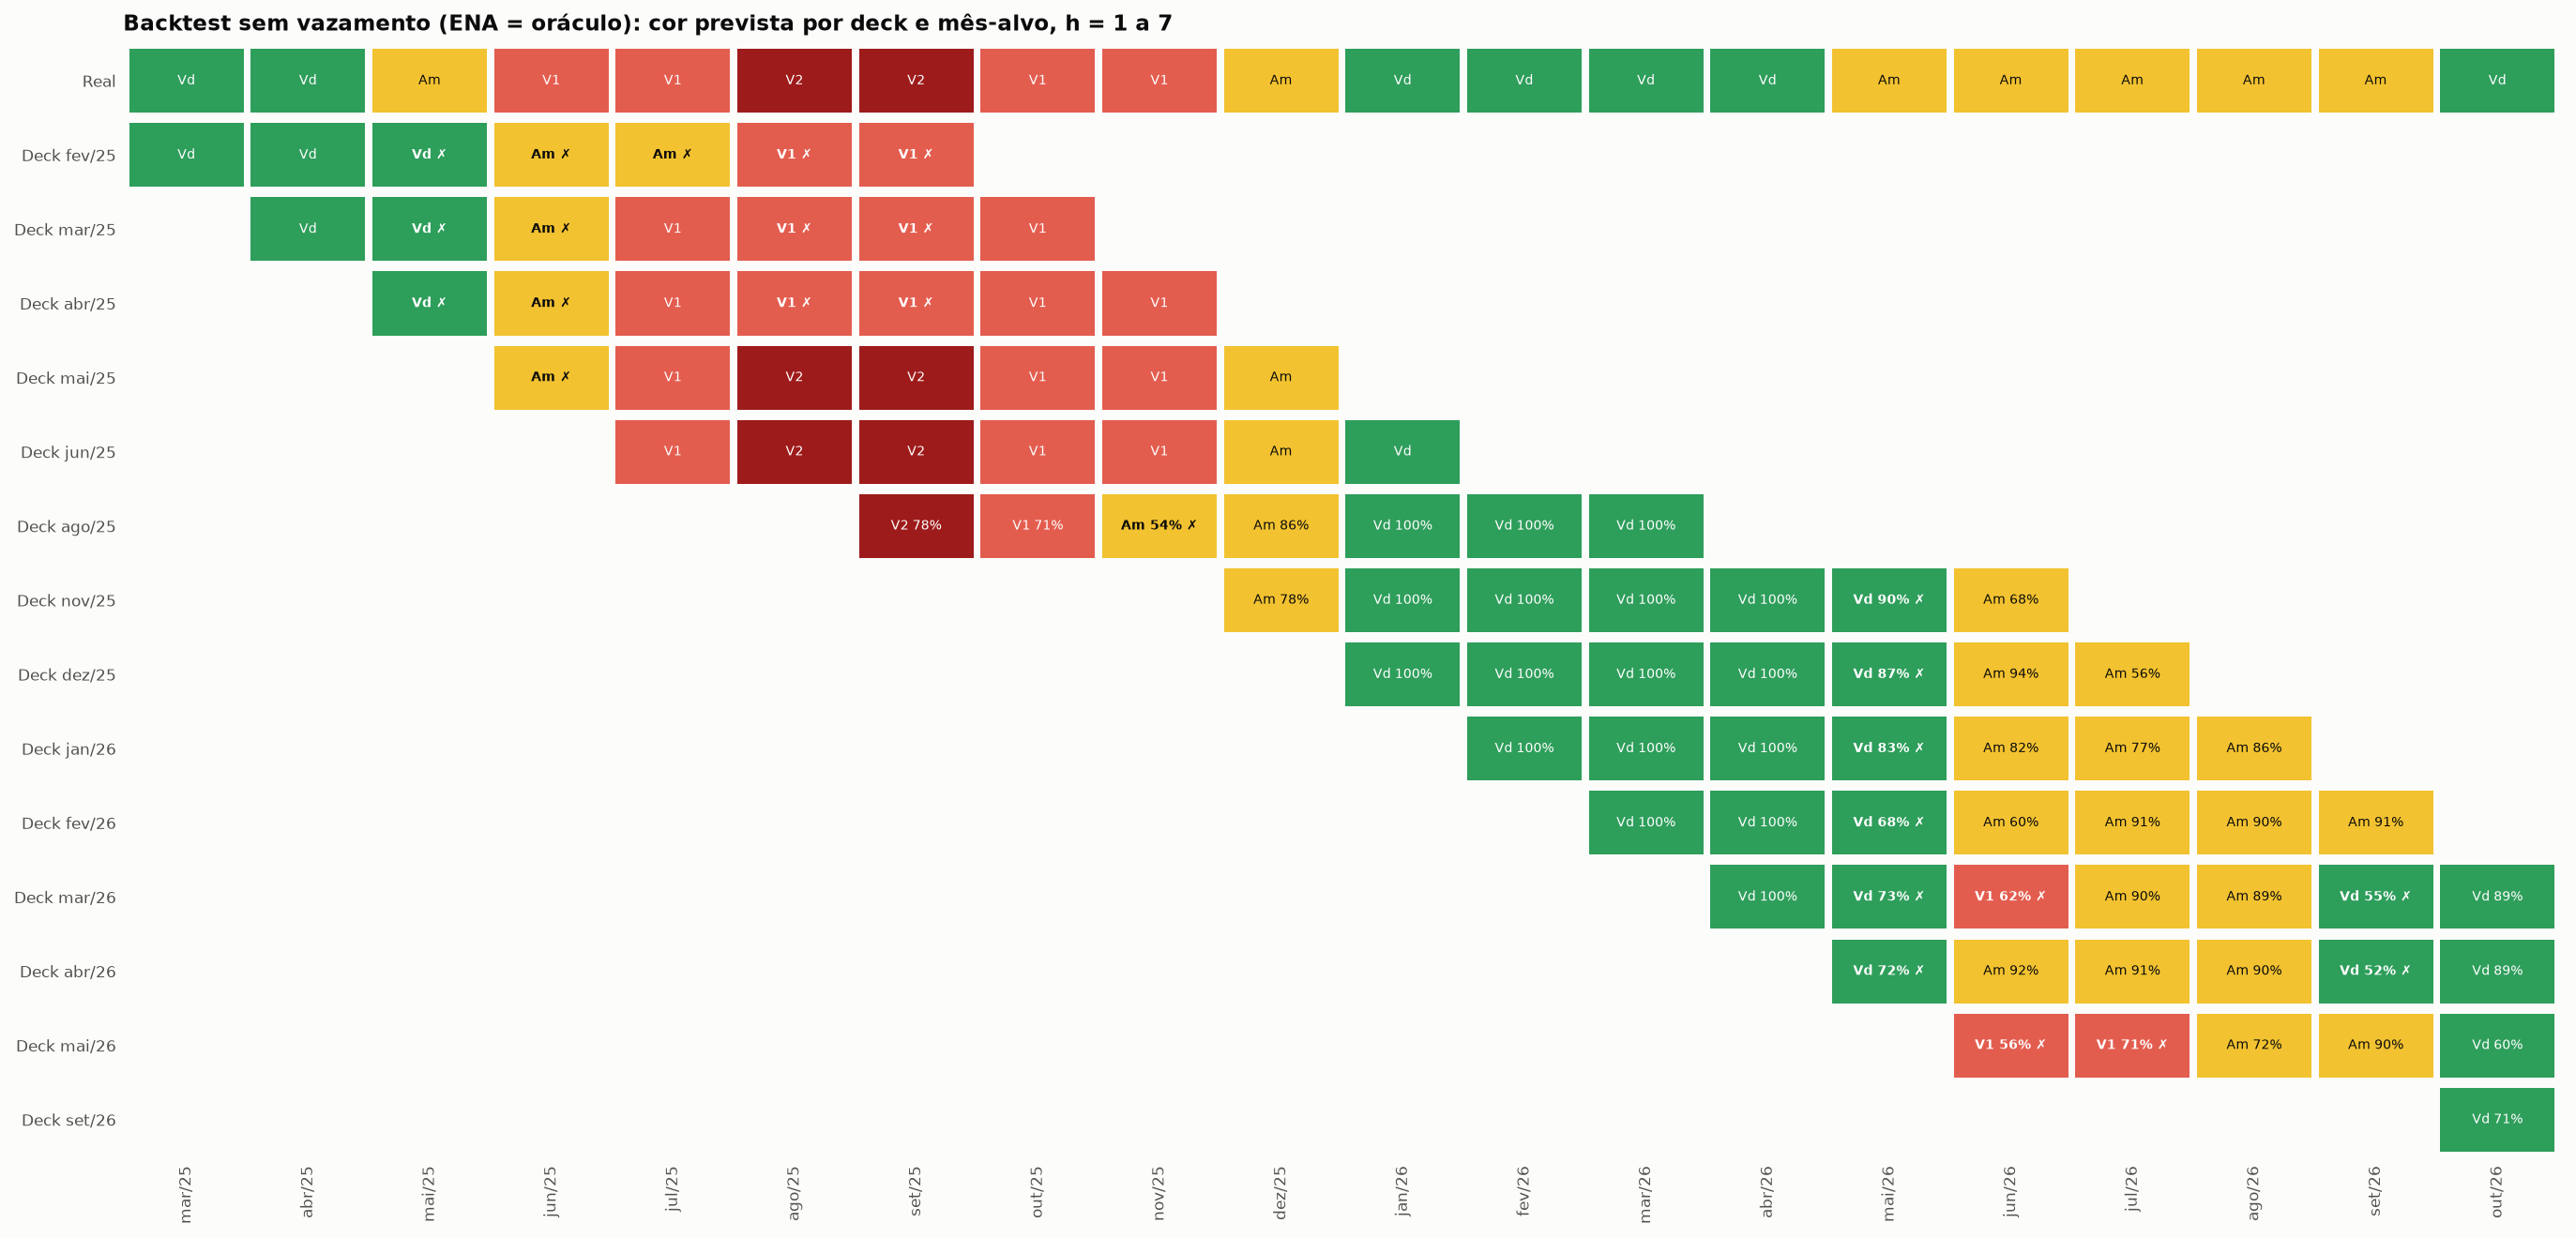

In [5]:
display(Image(graficos.matriz_backtest(
    t, "Backtest sem vazamento (ENA = oráculo): cor prevista por deck e mês-alvo, h = 1 a 7",
    "backtest_sem_vazamento/10_matriz_backtest.png")))

### Matriz ajustada: distribuição completa

Mesma metodologia; cada célula mostra a cor prevista (cor da média) e, embaixo, a probabilidade de cada cor (≥ 5%).

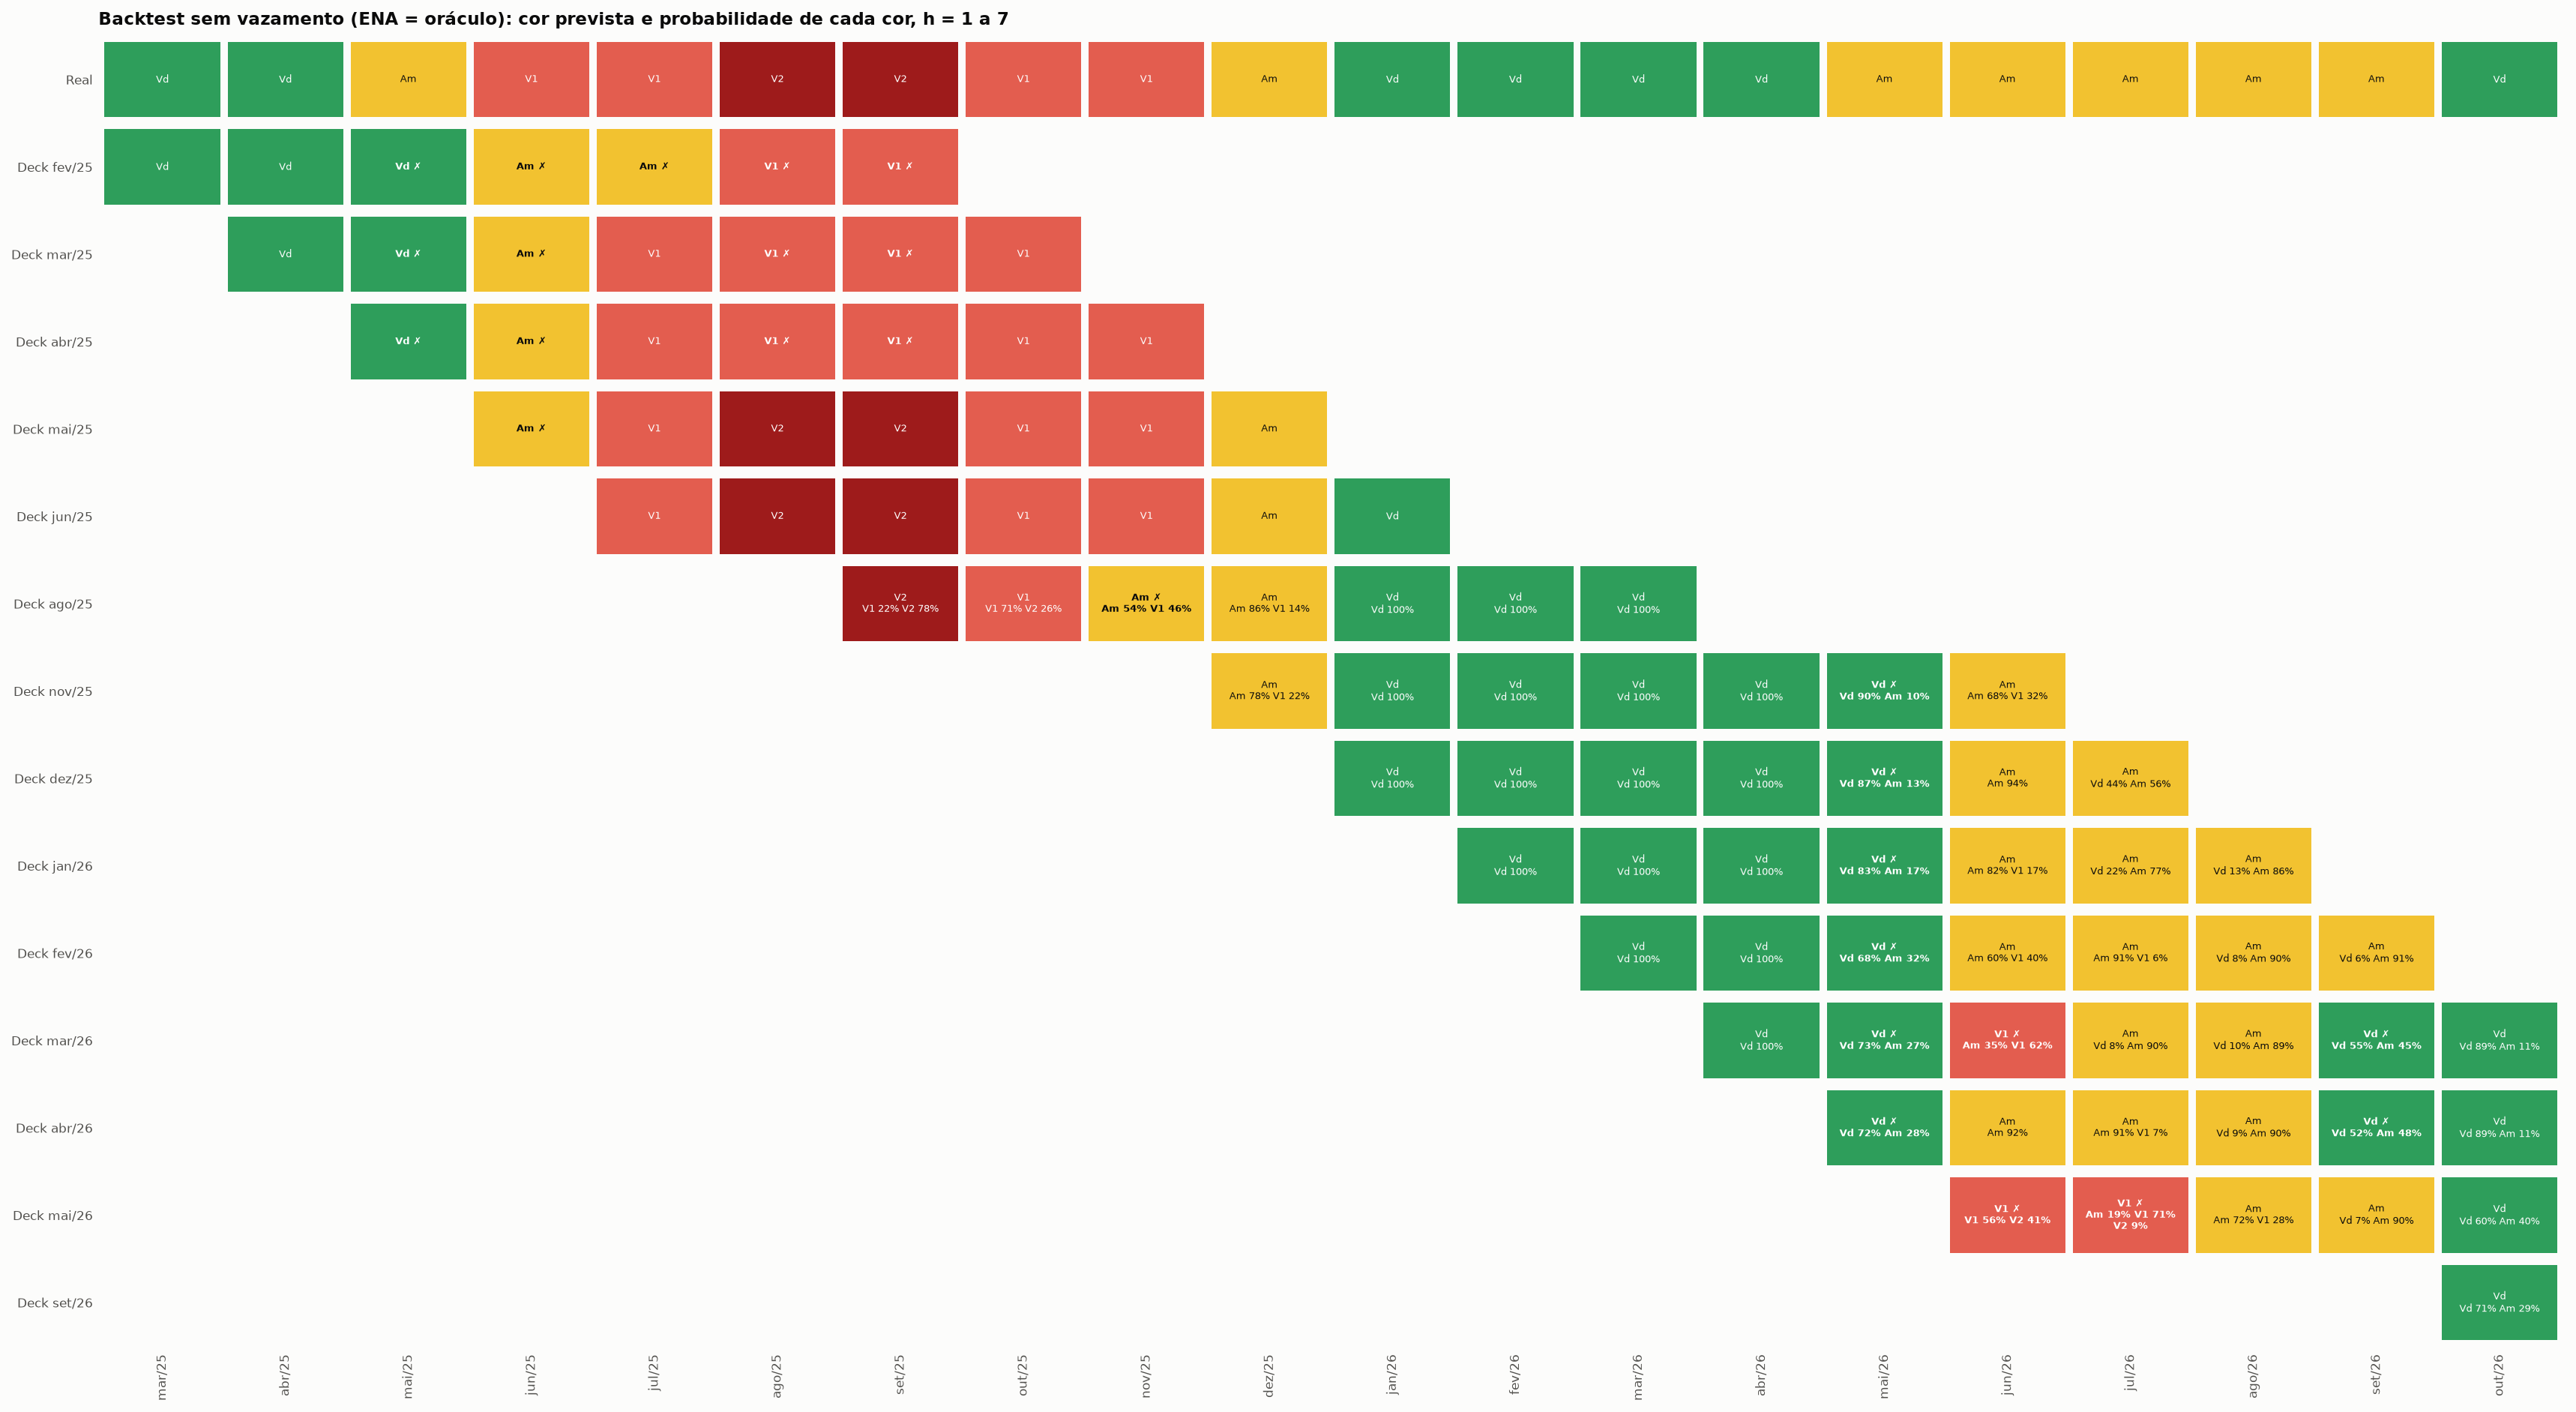

In [6]:
display(Image(graficos.matriz_backtest(
    t, "Backtest sem vazamento (ENA = oráculo): cor prevista e probabilidade de cada cor, h = 1 a 7",
    "backtest_sem_vazamento/10b_matriz_backtest_distribuicao.png", distribuicao=True)))

## 5. Onde estão os erros

In [7]:
erros = t[t.cor_media != t.cor_oficial]
print("erros por mês do ano do alvo:", erros.groupby(erros.alvo.dt.month).size().to_dict(), "de", len(erros))
print(f"nos erros: GSF previsto − real = {(erros.gsf_medio - erros.gsf_band_boletim).mean():+.3f} | "
      f"PLD previsto − real = {(erros.pld_medio - erros.pld_gatilho_boletim).mean():+.1f} R$/MWh")
erros[["deck", "alvo", "h", "cor_media", "cor_oficial", "gsf_medio", "gsf_band_boletim", "pld_medio", "pld_gatilho_boletim", "p_cor_real"]]

erros por mês do ano do alvo: {5: 9, 6: 6, 7: 2, 8: 3, 9: 5, 11: 1} de 26
nos erros: GSF previsto − real = +0.033 | PLD previsto − real = -42.6 R$/MWh


,deck,alvo,h,cor_media,cor_oficial,gsf_medio,gsf_band_boletim,pld_medio,pld_gatilho_boletim,p_cor_real
3,2025-02,2025-05,3,Verde,Amarela,0.880,0.830,168.975,241.890,NaN
4,2025-02,2025-06,4,Amarela,Vermelha 1,0.770,0.750,240.907,310.350,NaN
5,2025-02,2025-07,5,Amarela,Vermelha 1,0.700,0.650,228.792,228.450,NaN
6,2025-02,2025-08,6,Vermelha 1,Vermelha 2,0.680,0.630,262.506,310.300,NaN
7,2025-02,2025-09,7,Vermelha 1,Vermelha 2,0.680,0.690,258.462,315.540,NaN
10,2025-03,2025-05,2,Verde,Amarela,0.880,0.830,218.634,241.890,NaN
11,2025-03,2025-06,3,Amarela,Vermelha 1,0.760,0.750,278.822,310.350,NaN
13,2025-03,2025-08,5,Vermelha 1,Vermelha 2,0.680,0.630,271.343,310.300,NaN
14,2025-03,2025-09,6,Vermelha 1,Vermelha 2,0.680,0.690,285.932,315.540,NaN
17,2025-04,2025-05,1,Verde,Amarela,0.880,0.830,177.298,241.890,NaN
